# Data Mining of Olympic Athlete Events History  



### Project Overview
This comprehensive data mining project explores **120 Years of Olympic History (1896–2016)**. We leverage a robust pipeline of data cleaning, exploratory visual analysis, supervised classification models (ID3-style, CART, Random Forests, XGBoost, Naïve Bayes), unsupervised cluster analysis (K-Means, Agglomerative Hierarchical, DBSCAN), and advanced association rule mining algorithms (Apriori, FP-Growth, PCY, Multistage PCY, Multihash PCY) to uncover hidden patterns within athlete attributes, performances, and demographics.

In [2]:
%%capture --no-stdout --no-display
import warnings
import logging

# Force suppress all deprecation and background system warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.simplefilter("ignore", DeprecationWarning)

# Mute deprecation warnings from the python logger as well
logging.captureWarnings(True)
logging.getLogger("py.warnings").setLevel(logging.ERROR)

## Step 1: Environment Setup & Library Imports

In this section, we establish the workspace environment by importing necessary libraries. In a classical Data Mining pipeline (KDD - Knowledge Discovery in Databases), establishing dependencies is the foundation of the process.

### Key Libraries and Tools Used:
1. **Data Wrangling & Manipulation**: `pandas` and `numpy` form the core of our structured data handling, allowing matrix manipulation and vectorized operations on the dataset.
2. **Exploratory Data Analysis (EDA)**: `matplotlib` and `seaborn` translate structural metrics into human-readable visual representations.
3. **Supervised Learning**: `scikit-learn` libraries provide implementations of CART Decision Trees, Random Forests, and pipeline construction. `xgboost` handles gradient-boosted trees.
4. **Unsupervised Learning & Dimensionality Reduction**: `scikit-learn` clustering classes (`KMeans`, `AgglomerativeClustering`, `DBSCAN`) help group instances, while `PCA` projects high-dimensional metrics into a 2D space.
5. **Association Rule Mining**: `mlxtend` is loaded to handle frequent itemset extraction via Apriori and FP-Growth, which we will compare to our custom PCY-variant implementations.

In [3]:
# Install necessary modules silently
!pip -q install xgboost mlxtend

import warnings, time, math, itertools, hashlib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Preprocessing & Evaluation tools
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    silhouette_score
)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from xgboost import XGBClassifier

# Association Rule Mining tools
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Establish visualization styling parameters
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

## Step 2: Streamlining Data Ingestion

Data ingestion is the second step in the KDD pipeline. It involves pulling raw data from a storage source into the primary memory space for transformation.

### Data Source:
We ingest the **120 Years of Olympic History** dataset directly from a public repository. This dataset tracks historical records of athletes, including biological attributes (Age, Height, Weight), representation details (Team, NOC), and the ultimate sporting outcomes (Event, Sport, Medal achievements). We load this raw schema into a tabular `DataFrame` structure for subsequent data preparation steps.

In [4]:
# Remote location of raw CSV holding Olympic historical records
DATA_URL = "https://raw.githubusercontent.com/rgriff23/Olympic_history/master/data/athlete_events.csv"

# Read historical CSV dataset directly into pandas DataFrame
df = pd.read_csv(DATA_URL)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (271116, 15)


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


## Step 3: Initial Data Profiling & Structural Audit

Before applying preprocessing transformations, a data miner must perform a structured audit to evaluate data quality. This step reveals issues such as:
- **Missing Values**: Identifying gaps (null values) that could skew models or cause algorithms to fail.
- **Duplicate Records**: Flagging repeated records to prevent artificial inflation of patterns.
- **Data Type Mismatches**: Ensuring numerical features are continuous and categorical columns are treated as discrete categories.
- **Anomalies and Scales**: Auditing the range of continuous attributes (Age, Height, Weight) to verify statistical ranges are realistic.

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing values"))

print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

Column names:
['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games', 'Year', 'Season', 'City', 'Sport', 'Event', 'Medal']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB
\nMis

,Missing values
Medal,231333
Weight,62875
Height,60171
Age,9474
Sex,0
ID,0
Name,0
Team,0
NOC,0
Year,0


\nDuplicate rows: 1385
\nDescriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,271116.0,NaN,NaN,NaN,68248.954396,39022.286345,1.0,34643.0,68205.0,102097.25,135571.0
Name,271116,134732,Robert Tait McKenzie,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,271116,2,M,196594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,261642.0,NaN,NaN,NaN,25.556898,6.393561,10.0,21.0,24.0,28.0,97.0
Height,210945.0,NaN,NaN,NaN,175.33897,10.518462,127.0,168.0,175.0,183.0,226.0
Weight,208241.0,NaN,NaN,NaN,70.702393,14.34802,25.0,60.0,70.0,79.0,214.0
Team,271116,1184,United States,17847,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NOC,271116,230,USA,18853,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Games,271116,51,2000 Summer,13821,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,271116.0,NaN,NaN,NaN,1978.37848,29.877632,1896.0,1960.0,1988.0,2002.0,2016.0


## Step 4: Data Cleaning, Target Engineering, & Integrity Checks

Raw datasets are often incomplete, noisy, and inconsistent. This step addresses these issues through targeted cleaning:

### Preprocessing Strategies:
1. **Deduplication**: We drop exact duplicate records to ensure each unique athlete-event outcome is represented only once.
2. **Feature Standardization**: Stripping whitespaces and standardizing textual fields prevents identical categories from being split due to hidden spacing differences.
3. **Target Engineering**: Since our goal is binary classification (predicting whether an athlete successfully wins a medal), we map the raw, sparse `Medal` feature to a binary target variable `Won_Medal` (where 1 represents Gold/Silver/Bronze and 0 represents No Medal).
4. **Handling Structural Zeros & Nulls**: Extreme or negative values are marked as NaN, allowing the imputation strategy inside our machine learning pipelines to handle them cleanly without causing data leakage.

In [6]:
# Remove duplicate rows from raw data
data = df.drop_duplicates().copy()

# Standardize text strings in categorical fields
data.columns = data.columns.str.strip()
for col in ["Sex", "Team", "NOC", "Games", "Season", "City", "Sport", "Event", "Medal"]:
    if col in data.columns:
        data[col] = data[col].astype("string").str.strip()

# Engineer the target variable: 1 if the athlete won any medal, 0 otherwise
data["Won_Medal"] = data["Medal"].notna().astype(int)

# Mark impossible numerical values (<= 0) as NaN
for col in ["Age", "Height", "Weight"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
    data.loc[data[col] <= 0, col] = np.nan

# Replace missing values for non-classification descriptive analyses
data["Medal_Category"] = data["Medal"].fillna("No Medal").astype(str)
data["Sex"] = data["Sex"].fillna("Unknown").astype(str)
data["Season"] = data["Season"].fillna("Unknown").astype(str)
data["Sport"] = data["Sport"].fillna("Unknown").astype(str)
data["Team"] = data["Team"].fillna("Unknown").astype(str)

print("Cleaned shape:", data.shape)
print("Target distribution:")
display(data["Won_Medal"].value_counts().rename(index={0:"No Medal", 1:"Won Medal"}).to_frame("Records"))

Cleaned shape: (269731, 17)
Target distribution:


,Records
Won_Medal,
No Medal,229959
Won Medal,39772


## Step 5: Exploratory Data Analysis & Visualizations

Exploratory Data Analysis (EDA) is the process of visually summarizing datasets to uncover underlying patterns, detect anomalies, and test hypotheses.

### Visual Analysis Components:
1. **Univariate Distributions**: Visualizing biological parameters (like Age) and binary labels to identify imbalances in our targets.
2. **Categorical Counts**: Identifying the most active sports and historical medal frequencies.
3. **Bivariate Correlations**: Using a Pearson Correlation matrix heatmap to discover relationships between continuous attributes like Height, Weight, and Age, as well as their correlations with the target outcome `Won_Medal`.
4. **Temporal Patterns**: Tracking participation trends over time to observe growth in competitive records across Olympic history.

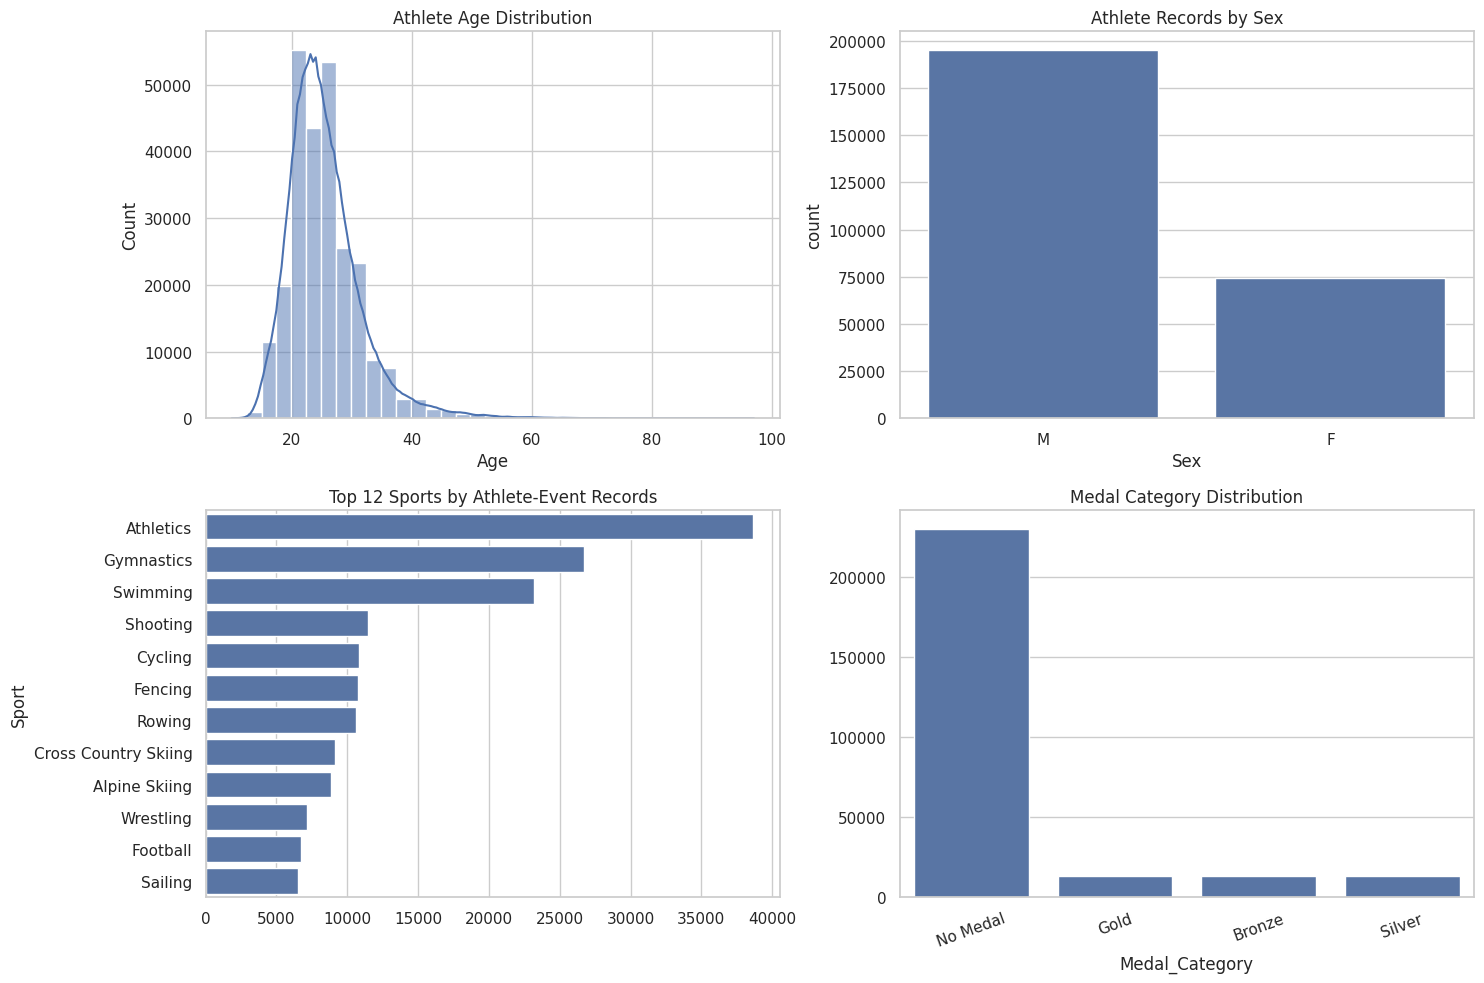

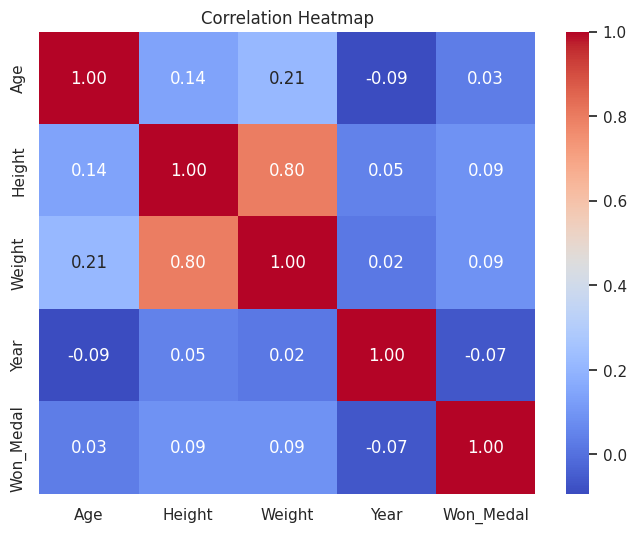

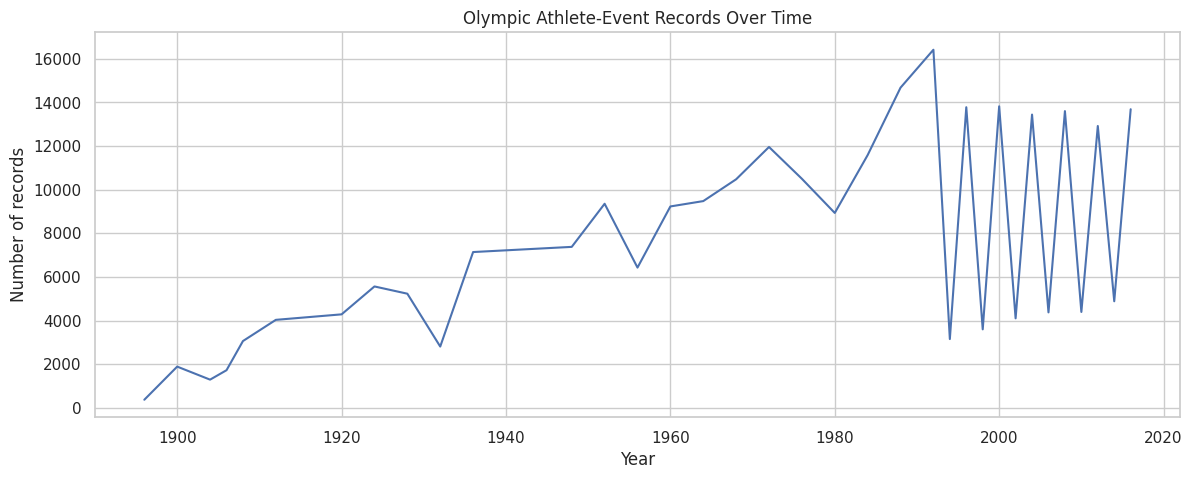

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(data["Age"].dropna(), bins=35, kde=True, ax=axes[0,0])
axes[0,0].set_title("Athlete Age Distribution")
sns.countplot(data=data, x="Sex", ax=axes[0,1])
axes[0,1].set_title("Athlete Records by Sex")
top_sports = data["Sport"].value_counts().head(12)
sns.barplot(x=top_sports.values, y=top_sports.index, ax=axes[1,0])
axes[1,0].set_title("Top 12 Sports by Athlete-Event Records")
medal_counts = data["Medal_Category"].value_counts()
sns.barplot(x=medal_counts.index, y=medal_counts.values, ax=axes[1,1])
axes[1,1].set_title("Medal Category Distribution")
axes[1,1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(data[["Age","Height","Weight","Year","Won_Medal"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

yearly = data.groupby("Year").size()
plt.figure(figsize=(14,5))
yearly.plot()
plt.title("Olympic Athlete-Event Records Over Time")
plt.xlabel("Year")
plt.ylabel("Number of records")
plt.show()

## Step 6: Dataset Partitioning & Pipeline Transformations

To build generalization models, we separate our dataset into independent **Training (80%)** and **Testing (20%)** sets. To ensure realistic evaluations, we implement **scikit-learn pipelines**:

### Pipeline Architecture:
1. **Data Leakage Prevention**: Imputation and scaling parameters are calculated solely on the training partition and then applied to the test partition.
2. **Numerical Pipeline**: We impute missing numeric biological features (Age, Height, Weight) using median values to handle outliers, followed by `StandardScaler` to normalize features with a mean of 0 and variance of 1.
3. **Categorical Pipeline**: We impute missing text fields using the mode (most frequent category), and encode them into numeric vectors using `OneHotEncoder`. We use threshold frequency limits to prune highly sparse, unique sports categories.

In [8]:
FEATURES = ["Sex", "Age", "Height", "Weight", "Year", "Season", "Sport"]
TARGET = "Won_Medal"

X = data[FEATURES].copy()
y = data[TARGET].copy()

categorical_features = ["Sex", "Season", "Sport"]
numeric_features = ["Age", "Height", "Weight", "Year"]

# Compatible with current scikit-learn versions
try:
    onehot = OneHotEncoder(handle_unknown="ignore", min_frequency=20)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", onehot)]), categorical_features)
    ],
    remainder="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("Training target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())

Training rows: 215784 | Testing rows: 53947
Training target proportions:


,Proportion
Won_Medal,
0,0.852552
1,0.147448


## Step 7: Classification Evaluation Metric Framework

Evaluating data mining classification models requires metrics beyond simple accuracy, especially when dealing with imbalanced datasets:

### Core Metrics Defined:
- **Accuracy**: The overall percentage of correct predictions. This metric can be misleading if one class dominates the dataset.
- **Precision**: Out of all predicted winners, what proportion actually won a medal? This measures the cost of false positives.
- **Recall (Sensitivity)**: Out of all actual medal winners, what proportion did the model correctly identify? This measures the cost of false negatives.
- **F1-Score**: The harmonic mean of Precision and Recall, providing a balanced single metric for evaluating performance on imbalanced classes.
- **Confusion Matrix**: A layout mapping true labels against predicted labels to show specific misclassifications.

In [9]:
classification_results = []

def evaluate_classifier(name, model, X_test, y_test, y_pred, elapsed):
    metrics = {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Training time (sec)": elapsed
    }
    classification_results.append(metrics)
    print(f"\\n{name} — Classification Report")
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No Medal","Won Medal"], cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.show()
    return metrics

## Step 8: ID3-Style Decision Tree Classification

We train a Decision Tree classifier using **Entropy / Information Gain** to simulate an ID3-like structure adapted to continuous features.

### Concept & Split Criteria:
- **Entropy**: Measures the impurity or randomness of target classes within a node:
  $$H(S) = -\sum p_i \log_2 p_i$$
- **Information Gain**: Calculated as the reduction in entropy achieved by partitioning the dataset on a given attribute.
- **Hyperparameter Adjustments**: Because the original ID3 algorithm does not natively support continuous variables or pruning, we limit `max_depth` and set `class_weight='balanced'` to prevent the tree from overfitting the majority 'No Medal' class.

\nID3-style (Entropy) — Classification Report
              precision    recall  f1-score   support

           0       0.92      0.57      0.70     45992
           1       0.22      0.69      0.33      7955

    accuracy                           0.59     53947
   macro avg       0.57      0.63      0.52     53947
weighted avg       0.81      0.59      0.65     53947



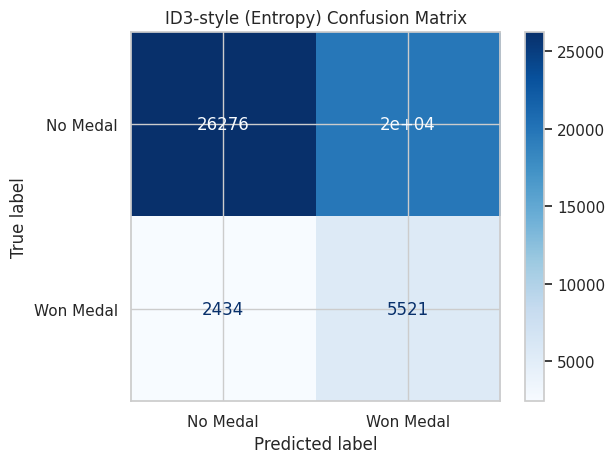

{'Algorithm': 'ID3-style (Entropy)',
 'Accuracy': 0.5894118301295717,
 'Precision': 0.2187660973966795,
 'Recall': 0.6940289126335638,
 'F1-score': 0.3326705230175946,
 'Training time (sec)': 2.5339369773864746}

In [10]:
id3_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy", max_depth=12, min_samples_leaf=20,
        class_weight="balanced", random_state=RANDOM_STATE
    ))
])

start = time.time()
id3_model.fit(X_train, y_train)
id3_time = time.time() - start
id3_pred = id3_model.predict(X_test)
evaluate_classifier("ID3-style (Entropy)", id3_model, X_test, y_test, id3_pred, id3_time)

## Step 9: CART Decision Tree Classification

The **CART (Classification and Regression Trees)** algorithm uses Gini Impurity rather than Entropy to evaluate candidate splits.

### Concept & Split Criteria:
- **Gini Impurity**: Measures the probability of a randomly chosen element being incorrectly labeled if it were randomly labeled according to the distribution in the subset:
  $$I_G(p) = 1 - \sum p_i^2$$
- **Algorithmic Differences**: Gini impurity is computationally faster than entropy because it avoids logarithmic calculations. This section trains a CART tree on the same balanced parameters to compare its performance against the ID3-style model.

\nCART (Gini) — Classification Report
              precision    recall  f1-score   support

           0       0.91      0.56      0.70     45992
           1       0.22      0.70      0.33      7955

    accuracy                           0.58     53947
   macro avg       0.57      0.63      0.51     53947
weighted avg       0.81      0.58      0.64     53947



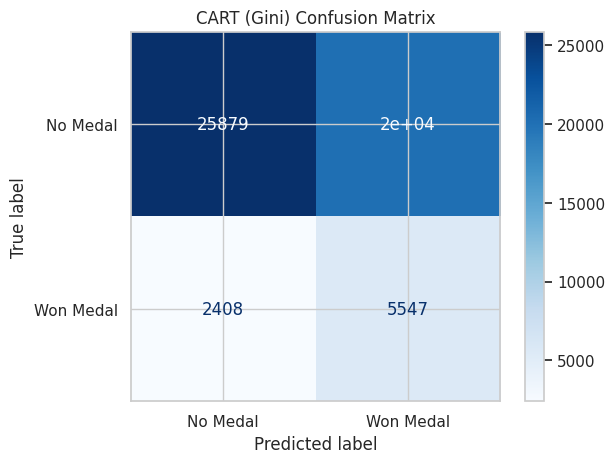

{'Algorithm': 'CART (Gini)',
 'Accuracy': 0.5825347099931414,
 'Precision': 0.2161730319563523,
 'Recall': 0.6972972972972973,
 'F1-score': 0.33003123605533247,
 'Training time (sec)': 2.5389230251312256}

In [11]:
cart_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini", max_depth=12, min_samples_leaf=20,
        class_weight="balanced", random_state=RANDOM_STATE
    ))
])

start = time.time()
cart_model.fit(X_train, y_train)
cart_time = time.time() - start
cart_pred = cart_model.predict(X_test)
evaluate_classifier("CART (Gini)", cart_model, X_test, y_test, cart_pred, cart_time)

## Step 10: Random Forest Classifier & Feature Importance Selection

**Random Forest** is an ensemble bagging method that builds multiple independent decision trees to improve model stability and accuracy.

### How It Works:
1. **Bootstrap Aggregating (Bagging)**: Each tree is trained on a random bootstrap sample of the training data.
2. **Feature Subspace Sampling**: At each split, only a random subset of features is considered, reducing correlation between individual trees.
3. **Feature Importance**: By measuring how much Gini impurity decreases across all trees when a feature is used for splitting, the model ranks feature importance, identifying which athlete attributes best predict success.

\nRandom Forest — Classification Report
              precision    recall  f1-score   support

           0       0.91      0.71      0.80     45992
           1       0.26      0.61      0.37      7955

    accuracy                           0.69     53947
   macro avg       0.59      0.66      0.58     53947
weighted avg       0.82      0.69      0.73     53947



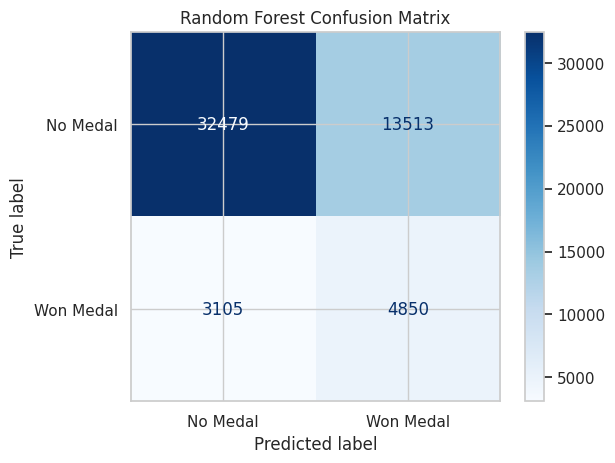

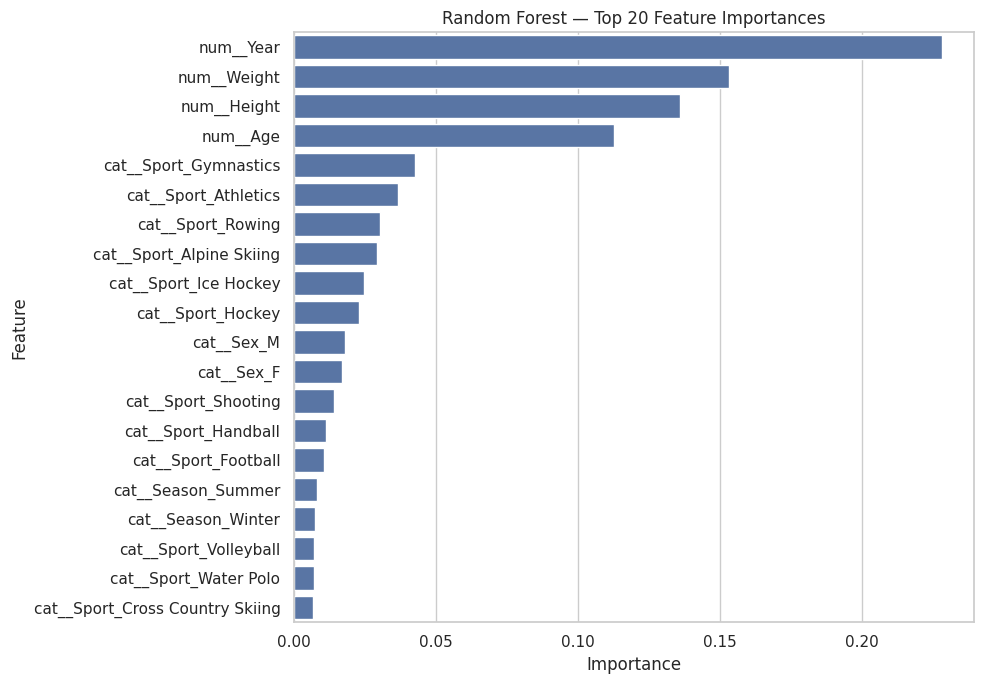

,Feature,Importance
3,num__Year,0.227964
2,num__Weight,0.153342
1,num__Height,0.136098
0,num__Age,0.112677
30,cat__Sport_Gymnastics,0.042807
11,cat__Sport_Athletics,0.036759
42,cat__Sport_Rowing,0.030285
8,cat__Sport_Alpine Skiing,0.029254
33,cat__Sport_Ice Hockey,0.024752
32,cat__Sport_Hockey,0.022912


In [12]:
rf_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150, max_depth=16, min_samples_leaf=10,
        class_weight="balanced_subsample", n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
rf_pred = rf_model.predict(X_test)
evaluate_classifier("Random Forest", rf_model, X_test, y_test, rf_pred, rf_time)

# Extract feature names after preprocessing
fitted_preprocessor = rf_model.named_steps["preprocess"]
try:
    feature_names = fitted_preprocessor.get_feature_names_out()
except Exception:
    feature_names = [f"Feature_{i}" for i in range(len(rf_model.named_steps["classifier"].feature_importances_))]

importances = rf_model.named_steps["classifier"].feature_importances_
rf_importance = pd.DataFrame({"Feature": feature_names, "Importance": importances})
rf_importance = rf_importance.sort_values("Importance", ascending=False).head(20)

plt.figure(figsize=(10,7))
sns.barplot(data=rf_importance, x="Importance", y="Feature")
plt.title("Random Forest — Top 20 Feature Importances")
plt.tight_layout()
plt.show()
display(rf_importance)

## Step 11: XGBoost Classification (Extreme Gradient Boosting)

**XGBoost (Extreme Gradient Boosting)** is a boosting algorithm that builds trees sequentially rather than independently.

### How It Works:
- **Sequential Correction**: Each new tree is trained to predict the residuals (errors) of the previous trees combined.
- **Regularized Objective**: The model includes regularization parameters ($L1$ and $L2$) within its loss function to penalize complexity, helping to prevent overfitting.
- **Optimization**: We use histogram-based splitting for fast, memory-efficient performance on large categorical and numerical features.

\nXGBoost — Classification Report
              precision    recall  f1-score   support

           0       0.86      1.00      0.92     45992
           1       0.73      0.06      0.11      7955

    accuracy                           0.86     53947
   macro avg       0.79      0.53      0.52     53947
weighted avg       0.84      0.86      0.80     53947



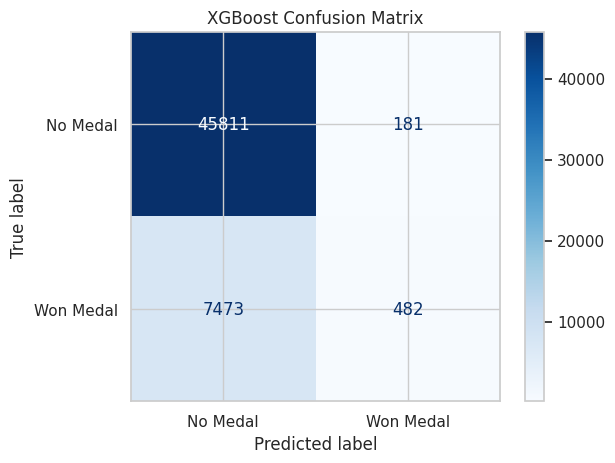

{'Algorithm': 'XGBoost',
 'Accuracy': 0.8581200066732163,
 'Precision': 0.726998491704374,
 'Recall': 0.06059082338152105,
 'F1-score': 0.11185889997679276,
 'Training time (sec)': 3.7978813648223877}

In [13]:
# XGBoost uses the same transformed features as the other models.
xgb_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.85,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE
    ))
])

start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
xgb_pred = xgb_model.predict(X_test)
evaluate_classifier("XGBoost", xgb_model, X_test, y_test, xgb_pred, xgb_time)

## Step 12: Naïve Bayes Probabilistic Classification

**Gaussian Naïve Bayes** is a classification model based on **Bayes' Theorem** with the strong assumption of feature independence.

### Mathematical Formulation:
$$P(Y|X_1, \dots, X_n) \propto P(Y) \prod_{i=1}^n P(X_i|Y)$$

### Core Characteristics:
- **Assumption**: It assumes features are conditionally independent given the class label, and continuous variables follow a normal distribution.
- **Efficiency**: Since Naïve Bayes only requires calculating class-conditional probability tables, it is highly scalable, fast to train, and provides a probabilistic baseline for model comparison.

\nNaïve Bayes — Classification Report
              precision    recall  f1-score   support

           0       0.86      0.96      0.91     45992
           1       0.32      0.11      0.16      7955

    accuracy                           0.83     53947
   macro avg       0.59      0.53      0.54     53947
weighted avg       0.78      0.83      0.80     53947



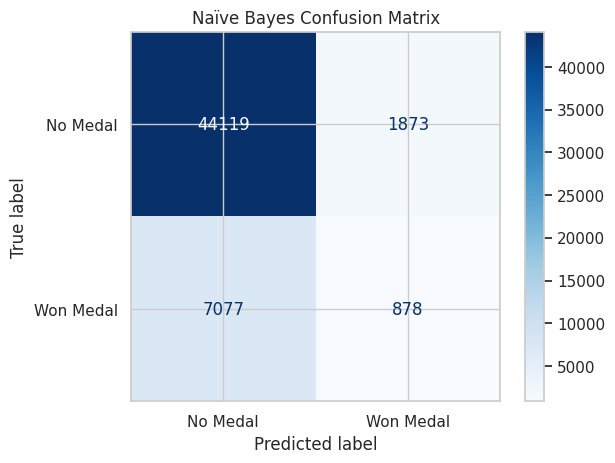

{'Algorithm': 'Naïve Bayes',
 'Accuracy': 0.8340964279756057,
 'Precision': 0.31915667030170847,
 'Recall': 0.1103708359522313,
 'F1-score': 0.1640201756024659,
 'Training time (sec)': 0.8976864814758301}

In [14]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import FunctionTransformer

# GaussianNB requires dense arrays instead of sparse matrices
nb_model = Pipeline([
    ("preprocess", preprocessor),
    ("to_dense", FunctionTransformer(lambda x: x.toarray() if hasattr(x, "toarray") else x, accept_sparse=True)),
    ("classifier", GaussianNB())
])

start = time.time()
nb_model.fit(X_train, y_train)
nb_time = time.time() - start
nb_pred = nb_model.predict(X_test)
evaluate_classifier("Naïve Bayes", nb_model, X_test, y_test, nb_pred, nb_time)

## Step 13: Supervised Classification Algorithm Comparison

This section aggregates the performance metrics of all our classification models into a single dataframe.

### Analytical Objectives:
- Compare accuracy, precision, recall, and F1-score across all algorithms.
- Visualize trade-offs, such as how balancing classes to prioritize recall can affect precision.
- Compare training latencies to understand the computational efficiency of each approach.

,Algorithm,Accuracy,Precision,Recall,F1-score,Training time (sec)
0,ID3-style (Entropy),0.5894,0.2188,0.6940,0.3327,2.5339
1,CART (Gini),0.5825,0.2162,0.6973,0.3300,2.5389
2,Random Forest,0.6920,0.2641,0.6097,0.3686,70.0548
3,XGBoost,0.8581,0.7270,0.0606,0.1119,3.7979
4,Naïve Bayes,0.8341,0.3192,0.1104,0.1640,0.8977


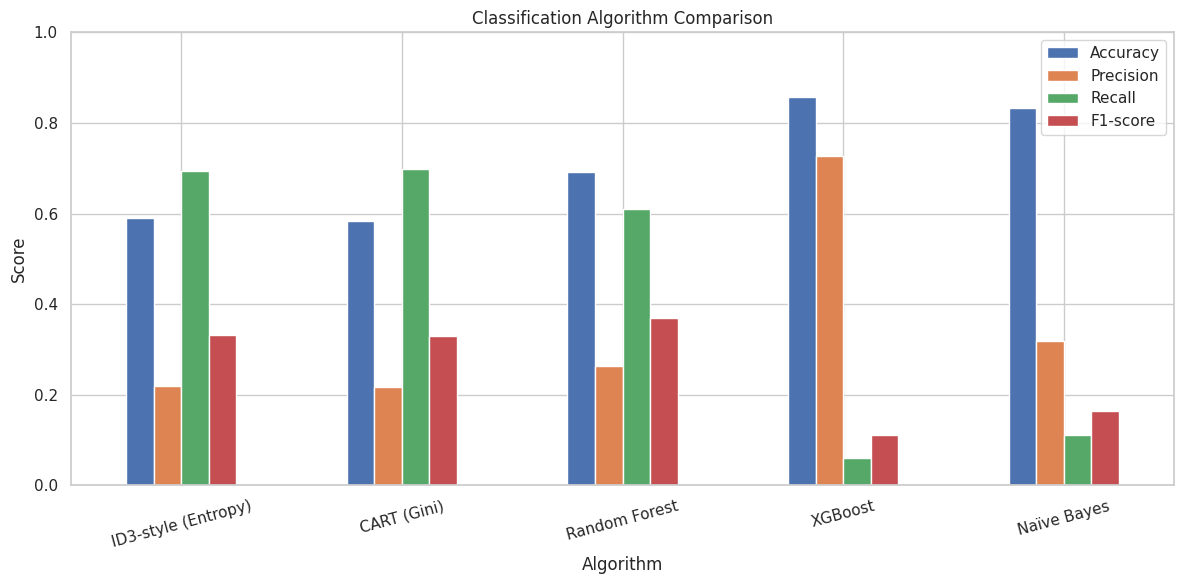

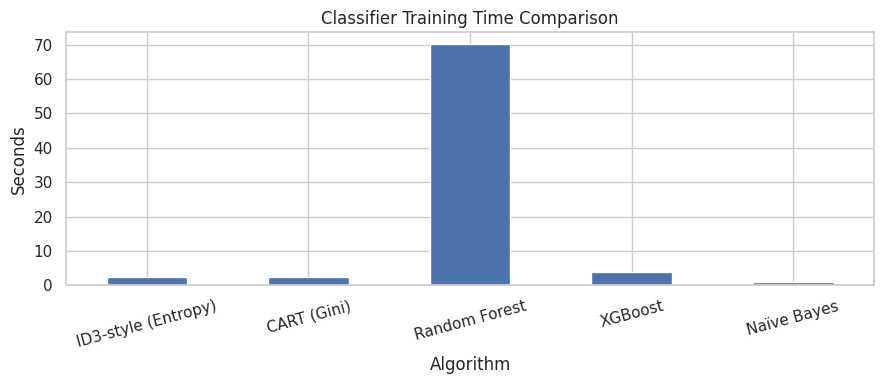

In [15]:
classification_comparison = pd.DataFrame(classification_results)
display(classification_comparison.round(4))

classification_comparison.set_index("Algorithm")[["Accuracy","Precision","Recall","F1-score"]].plot(
    kind="bar", figsize=(12,6), ylim=(0,1), rot=15
)
plt.title("Classification Algorithm Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

classification_comparison.set_index("Algorithm")["Training time (sec)"].plot(
    kind="bar", figsize=(9,4), rot=15
)
plt.title("Classifier Training Time Comparison")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

## Step 14: Data Wrangling for Unsupervised Clustering

Unsupervised clustering aims to discover natural groupings in data without relying on predefined labels. This section prepares athlete demographics for clustering.

### Preprocessing for Clustering:
1. **Feature Selection**: We isolate biological features (`Age`, `Height`, `Weight`) to group athletes by physical profile.
2. **Imputation & Scaling**: Missing values are filled, and standard scaling is applied. Because distance metrics are sensitive to feature scales, scaling is essential to prevent weight metrics from dominating age metrics.
3. **Sampling**: We extract a random sample of 15,000 records to reduce the memory footprint for computationally intensive algorithms.

In [16]:
cluster_source = data[["Age","Height","Weight"]].copy()
cluster_source = cluster_source.dropna(how="all")

cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

cluster_array = cluster_imputer.fit_transform(cluster_source)
cluster_array = cluster_scaler.fit_transform(cluster_array)

rng = np.random.RandomState(RANDOM_STATE)
sample_size = min(15000, len(cluster_array))
sample_idx = rng.choice(len(cluster_array), size=sample_size, replace=False)
X_cluster = cluster_array[sample_idx]

print("Clustering sample size:", X_cluster.shape[0])

Clustering sample size: 15000


## Step 15: K-Means Clustering & Hyperparameter Tuning via Silhouette Evaluation

**K-Means** is a distance-based clustering algorithm that partitions data into $K$ distinct, non-overlapping clusters.

### Clustering Validation Metrics:
- **Elbow Method (WCSS)**: Measures the sum of squared distances from each point to its assigned cluster center. We look for an 'elbow' where adding more clusters yields diminishing returns in WCSS reduction.
- **Silhouette Coefficient**: Evaluates cluster separation and cohesion. For a given point $i$:
  $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
  where $a(i)$ is the mean distance to points in the same cluster, and $b(i)$ is the mean distance to points in the nearest neighboring cluster. We run K-Means across several values of $K$ and select the one with the highest silhouette score.

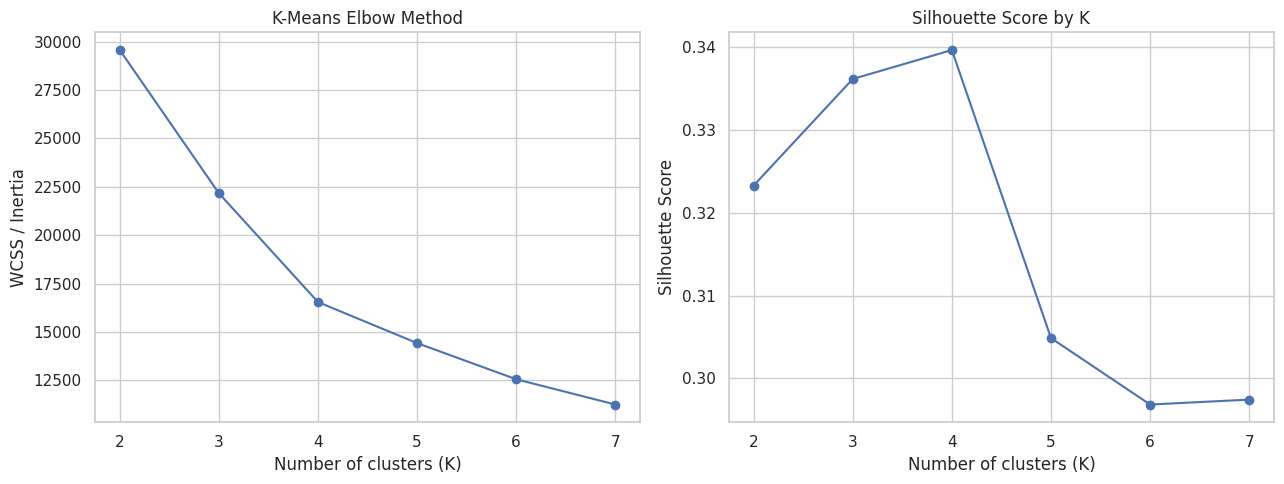

K selected using highest tested silhouette score: 4
K-Means silhouette score: 0.3397


In [17]:
inertias, silhouette_values = [], []
k_values = range(2, 8)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouette_values.append(silhouette_score(X_cluster, labels, sample_size=min(4000, len(X_cluster)), random_state=RANDOM_STATE))

fig, axes = plt.subplots(1,2, figsize=(13,5))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("WCSS / Inertia")
axes[1].plot(list(k_values), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_values))]
print("K selected using highest tested silhouette score:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster)
print("K-Means silhouette score:", round(silhouette_score(X_cluster, kmeans_labels, sample_size=min(4000, len(X_cluster)), random_state=RANDOM_STATE), 4))


## Step 16: Agglomerative Hierarchical Clustering & Dendrogram

**Hierarchical Clustering** constructs a nested tree of clusters bottom-up (agglomerative).

### How It Works:
1. **Initial State**: Every individual data point starts as its own separate cluster.
2. **Linkage Criterion**: We use **Ward's Linkage**, which minimizes the total within-cluster variance when merging cluster pairs.
3. **Dendrogram Visualization**: This tree diagram illustrates the sequence of merges and the relative distances between clusters, helping us visually inspect the cluster divisions.

Agglomerative clusters: 4
Agglomerative silhouette score: 0.2932
Execution time (sec): 0.16


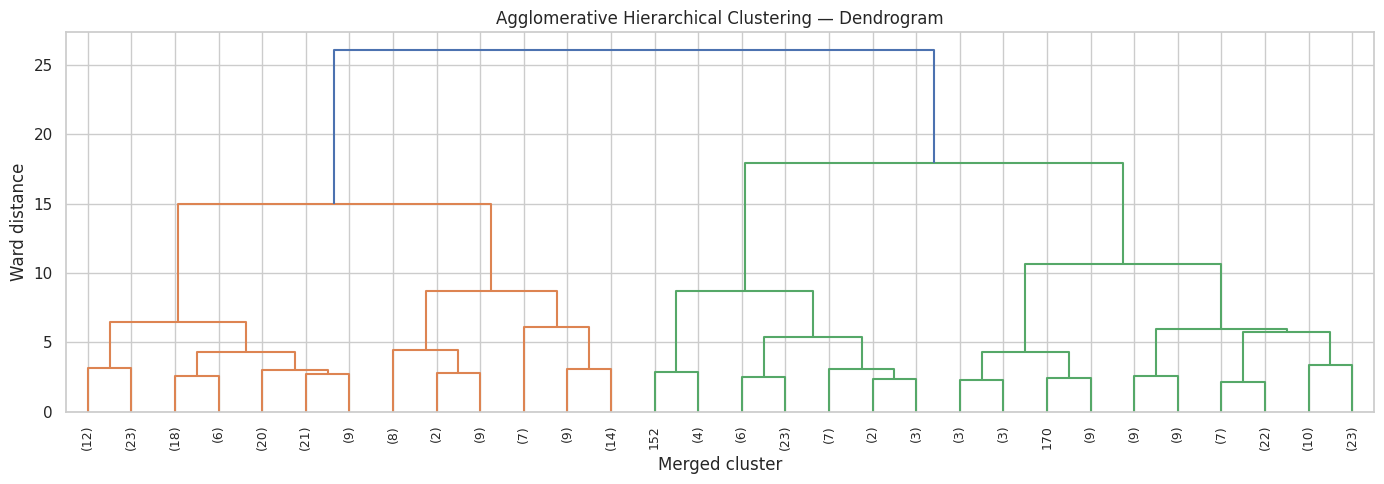

In [18]:
# Use a smaller subset for hierarchical clustering and dendrogram.
hier_size = min(2000, len(X_cluster))
X_hier = X_cluster[:hier_size]

start = time.time()
hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hier_labels = hierarchical.fit_predict(X_hier)
hier_time = time.time() - start

print("Agglomerative clusters:", len(np.unique(hier_labels)))
print("Agglomerative silhouette score:", round(silhouette_score(X_hier, hier_labels), 4))
print("Execution time (sec):", round(hier_time, 2))

# Dendrogram on a smaller subset to keep plotting readable
dendro_size = min(300, len(X_hier))
Z = linkage(X_hier[:dendro_size], method="ward")
plt.figure(figsize=(14,5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9)
plt.title("Agglomerative Hierarchical Clustering — Dendrogram")
plt.xlabel("Merged cluster")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

## Step 17: DBSCAN Clustering & Outlier/Noise Detection

**DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** groups points based on density, making it robust at finding arbitrary cluster shapes and detecting outliers.

### Core Parameters:
- **Epsilon (eps)**: The maximum distance radius used to define a neighborhood.
- **MinSamples**: The minimum number of points required within an epsilon neighborhood to form a core point.
- **Outlier Detection**: Points in low-density areas that do not belong to any cluster are labeled as noise (-1), which we project onto a 2D space using Principal Component Analysis (PCA).

DBSCAN clusters (excluding noise): 1
Noise / outlier points: 101
Noise percentage: 0.67 %
Execution time (sec): 0.62
Silhouette score skipped: DBSCAN found fewer than two non-noise clusters.


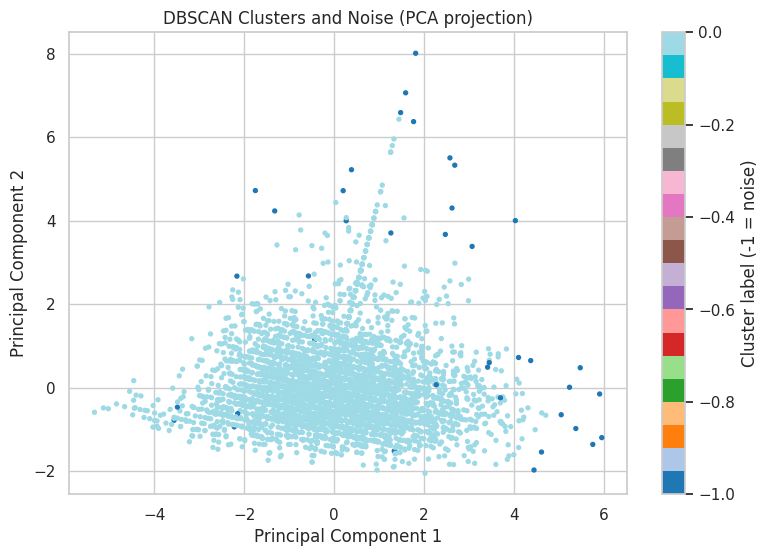

In [19]:
# DBSCAN parameters may need tuning for a different sample/data distribution.
start = time.time()
dbscan = DBSCAN(eps=0.65, min_samples=12, n_jobs=-1)
db_labels = dbscan.fit_predict(X_cluster)
db_time = time.time() - start

unique_labels = set(db_labels)
n_clusters_db = len(unique_labels - {-1})
n_noise = int(np.sum(db_labels == -1))

print("DBSCAN clusters (excluding noise):", n_clusters_db)
print("Noise / outlier points:", n_noise)
print("Noise percentage:", round(100*n_noise/len(db_labels), 2), "%")
print("Execution time (sec):", round(db_time, 2))

non_noise_mask = db_labels != -1
if n_clusters_db >= 2 and non_noise_mask.sum() > 2:
    print("DBSCAN silhouette (excluding noise):",
          round(silhouette_score(X_cluster[non_noise_mask], db_labels[non_noise_mask],
                                 sample_size=min(4000, non_noise_mask.sum()), random_state=RANDOM_STATE), 4))
else:
    print("Silhouette score skipped: DBSCAN found fewer than two non-noise clusters.")

# Visualize clusters using PCA projection
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_cluster)
plot_idx = rng.choice(len(X_2d), size=min(5000, len(X_2d)), replace=False)

plt.figure(figsize=(9,6))
scatter = plt.scatter(X_2d[plot_idx,0], X_2d[plot_idx,1], c=db_labels[plot_idx], s=8, cmap="tab20")
plt.title("DBSCAN Clusters and Noise (PCA projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster label (-1 = noise)")
plt.show()

## Step 18: Association Rule Mining — Transaction Preparation

Association rule mining extracts interesting relationships and co-occurrences from transactional datasets.

### Transaction Engineering:
To find relationships among athlete attributes, we convert our categorical columns into categorical transactions. Each athlete-event record is transformed into a transaction (e.g., `['Sport=Gymnastics', 'Sex=M', 'Team=Other Team', 'Season=Summer', 'Medal=No Medal']`), which we then analyze using frequent itemset mining algorithms.

In [20]:
assoc = data[["Sport","Sex","Team","Season","Medal_Category"]].copy()

TOP_SPORTS = 25
TOP_TEAMS = 25
popular_sports = assoc["Sport"].value_counts().head(TOP_SPORTS).index
popular_teams = assoc["Team"].value_counts().head(TOP_TEAMS).index

assoc["Sport"] = assoc["Sport"].where(assoc["Sport"].isin(popular_sports), "Other Sport")
assoc["Team"] = assoc["Team"].where(assoc["Team"].isin(popular_teams), "Other Team")

assoc_sample = assoc.sample(n=min(30000, len(assoc)), random_state=RANDOM_STATE)

transactions = []
for row in assoc_sample.itertuples(index=False, name=None):
    sport, sex, team, season, medal = row
    transactions.append([
        "Sport=" + str(sport),
        "Sex=" + str(sex),
        "Team=" + str(team),
        "Season=" + str(season),
        "Medal=" + str(medal)
    ])

print("Number of transactions:", len(transactions))
print("Example transaction:", transactions[0])

Number of transactions: 30000
Example transaction: ['Sport=Gymnastics', 'Sex=M', 'Team=Other Team', 'Season=Summer', 'Medal=No Medal']


## Step 19: Apriori Frequent Itemsets & Rules Generation

The **Apriori** algorithm identifies frequent itemsets by leveraging the **Apriori Property** (downward closure).

### Key Concepts:
- **Apriori Property**: All non-empty subsets of a frequent itemset must also be frequent. If an itemset is infrequent, all of its supersets will also be infrequent, allowing us to prune candidates early.
- **Support**: The fraction of total transactions containing the itemset:
  $$\text{Support}(A \rightarrow B) = P(A \cup B)$$
- **Confidence**: How often the rule is true:
  $$\text{Confidence}(A \rightarrow B) = \frac{P(A \cup B)}{P(A)}$$
- **Lift**: Measures how much more often $A$ and $B$ occur together than expected if they were statistically independent:
  $$\text{Lift}(A \rightarrow B) = \frac{P(A \cup B)}{P(A)P(B)}$$

In [21]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_array, columns=te.columns_)

start = time.time()
apriori_itemsets = apriori(basket, min_support=0.015, use_colnames=True, max_len=3)
apriori_time = time.time() - start

print("Apriori frequent itemsets:", len(apriori_itemsets))
print("Execution time (sec):", round(apriori_time, 2))
display(apriori_itemsets.sort_values("support", ascending=False).head(15))

if len(apriori_itemsets):
    apriori_rules = association_rules(apriori_itemsets, metric="confidence", min_threshold=0.20)
    apriori_rules = apriori_rules.sort_values(["lift","confidence"], ascending=False)
    display(apriori_rules[["antecedents","consequents","support","confidence","lift"]].head(15))
else:
    apriori_rules = pd.DataFrame()
    print("No itemsets found. Lower min_support and rerun.")

Apriori frequent itemsets: 308
Execution time (sec): 0.49


,support,itemsets
2,0.855500,(Medal=No Medal)
4,0.817867,(Season=Summer)
7,0.725100,(Sex=M)
58,0.693833,"(Season=Summer, Medal=No Medal)"
61,0.623133,"(Sex=M, Medal=No Medal)"
101,0.601100,"(Sex=M, Season=Summer)"
189,0.512667,"(Sex=M, Season=Summer, Medal=No Medal)"
44,0.360500,(Team=Other Team)
92,0.322933,"(Team=Other Team, Medal=No Medal)"
129,0.307333,"(Season=Summer, Team=Other Team)"


,antecedents,consequents,support,confidence,lift
503,(Sport=Ice Hockey),"(Season=Winter, Sex=M)",0.017167,0.838762,6.764211
254,(Sport=Alpine Skiing),"(Season=Winter, Medal=No Medal)",0.032200,0.964072,5.963331
257,(Sport=Biathlon),"(Season=Winter, Medal=No Medal)",0.017533,0.917976,5.678199
260,(Sport=Cross Country Skiing),"(Season=Winter, Medal=No Medal)",0.032200,0.914773,5.658388
268,(Sport=Speed Skating),"(Season=Winter, Medal=No Medal)",0.017333,0.896552,5.545681
91,(Sport=Alpine Skiing),(Season=Winter),0.033400,1.000000,5.490483
92,(Sport=Biathlon),(Season=Winter),0.019100,1.000000,5.490483
93,(Sport=Cross Country Skiing),(Season=Winter),0.035200,1.000000,5.490483
97,(Sport=Speed Skating),(Season=Winter),0.019333,1.000000,5.490483
253,"(Sport=Alpine Skiing, Medal=No Medal)",(Season=Winter),0.032200,1.000000,5.490483


## Step 20: FP-Growth Frequent Itemsets & Rules Generation

**FP-Growth (Frequent Pattern Growth)** is an association mining algorithm that avoids the costly candidate generation step used in Apriori.

### How It Works:
1. **FP-Tree Construction**: Compresses the transactional database into a compact, trie-like prefix tree.
2. **Conditional Databases**: Divides the compressed tree into conditional databases to mine frequent patterns directly.
3. **Performance**: Since it avoids repeatedly scanning the database and generating candidate itemsets, it is typically much faster than Apriori on large datasets.

In [22]:
start = time.time()
fp_itemsets = fpgrowth(basket, min_support=0.015, use_colnames=True, max_len=3)
fp_time = time.time() - start

print("FP-Growth frequent itemsets:", len(fp_itemsets))
print("Execution time (sec):", round(fp_time, 2))
display(fp_itemsets.sort_values("support", ascending=False).head(15))

if len(fp_itemsets):
    fp_rules = association_rules(fp_itemsets, metric="confidence", min_threshold=0.20)
    fp_rules = fp_rules.sort_values(["lift","confidence"], ascending=False)
    display(fp_rules[["antecedents","consequents","support","confidence","lift"]].head(15))
else:
    fp_rules = pd.DataFrame()
    print("No itemsets found. Lower min_support and rerun.")

FP-Growth frequent itemsets: 308
Execution time (sec): 18.97


,support,itemsets
0,0.855500,(Medal=No Medal)
1,0.817867,(Season=Summer)
2,0.725100,(Sex=M)
54,0.693833,"(Season=Summer, Medal=No Medal)"
55,0.623133,"(Sex=M, Medal=No Medal)"
56,0.601100,"(Sex=M, Season=Summer)"
57,0.512667,"(Sex=M, Season=Summer, Medal=No Medal)"
3,0.360500,(Team=Other Team)
58,0.322933,"(Team=Other Team, Medal=No Medal)"
59,0.307333,"(Season=Summer, Team=Other Team)"


,antecedents,consequents,support,confidence,lift
330,(Sport=Ice Hockey),"(Season=Winter, Sex=M)",0.017167,0.838762,6.764211
218,(Sport=Alpine Skiing),"(Season=Winter, Medal=No Medal)",0.032200,0.964072,5.963331
491,(Sport=Biathlon),"(Season=Winter, Medal=No Medal)",0.017533,0.917976,5.678199
406,(Sport=Cross Country Skiing),"(Season=Winter, Medal=No Medal)",0.032200,0.914773,5.658388
466,(Sport=Speed Skating),"(Season=Winter, Medal=No Medal)",0.017333,0.896552,5.545681
213,(Sport=Alpine Skiing),(Season=Winter),0.033400,1.000000,5.490483
217,"(Sport=Alpine Skiing, Medal=No Medal)",(Season=Winter),0.032200,1.000000,5.490483
220,"(Sport=Alpine Skiing, Sex=M)",(Season=Winter),0.019933,1.000000,5.490483
401,(Sport=Cross Country Skiing),(Season=Winter),0.035200,1.000000,5.490483
405,"(Sport=Cross Country Skiing, Medal=No Medal)",(Season=Winter),0.032200,1.000000,5.490483


## Step 21: PCY (Park-Chen-Yu) Algorithm for Frequent Pairs

The **PCY Algorithm** is an optimization of Apriori designed to reduce memory usage during the candidate pair generation phase.

### Algorithmic Mechanics:
- **Pass 1**: Along with counting individual items, PCY hashes every pair of items in each transaction into a hash table bucket array. If a bucket's count exceeds the minimum support threshold, its bit is set to 1 in a frequent-bucket bitmap.
- **Pass 2**: When generating candidate pairs, a pair $(A, B)$ is only counted if both individual items $A$ and $B$ are frequent, **and** their hash bucket has its bit set to 1 in the bitmap, significantly reducing the number of candidate pairs to track in memory.

In [23]:
from collections import Counter
from itertools import combinations

def pair_hash(a, b, seed, bucket_count):
    key = f"{seed}|{a}|{b}".encode("utf-8")
    digest = hashlib.blake2b(key, digest_size=8).digest()
    return int.from_bytes(digest, "big") % bucket_count

def pcy(transactions, min_support_count, bucket_count=5000, seed=17):
    item_counts = Counter()
    bucket_counts = np.zeros(bucket_count, dtype=np.int64)

    # Pass 1: singleton counts + pair hash bucket counts
    for transaction in transactions:
        items = sorted(set(transaction))
        item_counts.update(items)
        for a, b in combinations(items, 2):
            h = (pair_hash(a, b, seed, bucket_count))
            bucket_counts[h] += 1

    frequent_items = {item for item, count in item_counts.items() if count >= min_support_count}
    frequent_buckets = bucket_counts >= min_support_count

    # Pass 2: count candidate pairs that pass both filters
    pair_counts = Counter()
    candidates_considered = 0
    for transaction in transactions:
        items = sorted(set(transaction).intersection(frequent_items))
        for a, b in combinations(items, 2):
            h = pair_hash(a, b, seed, bucket_count)
            if frequent_buckets[h]:
                candidates_considered += 1
                pair_counts[(a, b)] += 1

    frequent_pairs = [(pair, count) for pair, count in pair_counts.items()
                      if count >= min_support_count]
    frequent_pairs.sort(key=lambda x: x[1], reverse=True)

    return {
        "frequent_items": frequent_items,
        "bucket_counts": bucket_counts,
        "frequent_pairs": frequent_pairs,
        "candidates_considered": candidates_considered
    }

min_support_fraction = 0.015
min_support_count = math.ceil(min_support_fraction * len(transactions))

start = time.time()
pcy_result = pcy(transactions, min_support_count, bucket_count=5000)
pcy_time = time.time() - start

print("Minimum support count:", min_support_count)
print("Frequent singleton items:", len(pcy_result["frequent_items"]))
print("Frequent pairs:", len(pcy_result["frequent_pairs"]))
print("Candidate pair occurrences counted in pass 2:", pcy_result["candidates_considered"])
print("PCY execution time (sec):", round(pcy_time, 2))

pcy_pairs_df = pd.DataFrame([
    {"Itemset": pair, "Support Count": count, "Support": count/len(transactions)}
    for pair, count in pcy_result["frequent_pairs"]
])
display(pcy_pairs_df.head(20))

Minimum support count: 450
Frequent singleton items: 54
Frequent pairs: 132
Candidate pair occurrences counted in pass 2: 238704
PCY execution time (sec): 1.23


,Itemset,Support Count,Support
0,"(Medal=No Medal, Season=Summer)",20815,0.693833
1,"(Medal=No Medal, Sex=M)",18694,0.623133
2,"(Season=Summer, Sex=M)",18033,0.601100
3,"(Medal=No Medal, Team=Other Team)",9688,0.322933
4,"(Season=Summer, Team=Other Team)",9220,0.307333
5,"(Sex=M, Team=Other Team)",8251,0.275033
6,"(Medal=No Medal, Sex=F)",6971,0.232367
7,"(Season=Summer, Sex=F)",6503,0.216767
8,"(Medal=No Medal, Season=Winter)",4850,0.161667
9,"(Season=Summer, Sport=Athletics)",4239,0.141300


## Step 22: Multistage PCY Algorithm

The **Multistage PCY** algorithm extends the PCY approach by using multiple sequential passes with independent hash functions to further reduce candidate pairs.

### Algorithmic Mechanics:
- **Pass 1**: Counts individual items and hashes pairs to build the first hash table and bitmap.
- **Pass 2**: Hashes pairs again using a **different** hash function. Crucially, it only increments bucket counts for pairs that successfully passed the first bitmap from Pass 1, resulting in a much sparser second hash table.
- **Pass 3**: Only counts the support for candidate pairs that successfully pass both bitmaps, minimizing memory usage during the final count.

In [24]:
def multistage_pcy(transactions, min_support_count, bucket_count=5000, seeds=(31, 97)):
    item_counts = Counter()
    bucket1 = np.zeros(bucket_count, dtype=np.int64)

    # Pass 1: count singles and first hash table
    for transaction in transactions:
        items = sorted(set(transaction))
        item_counts.update(items)
        for a, b in combinations(items, 2):
            bucket1[hash((a, b, seeds[0])) % bucket_count] += 1

    frequent_items = {i for i,c in item_counts.items() if c >= min_support_count}
    bitmap1 = bucket1 >= min_support_count

    # Pass 2: second hash table only for pairs passing stage 1
    bucket2 = np.zeros(bucket_count, dtype=np.int64)
    for transaction in transactions:
        items = sorted(set(transaction).intersection(frequent_items))
        for a, b in combinations(items, 2):
            if bitmap1[hash((a,b,seeds[0])) % bucket_count]:
                bucket2[hash((a,b,seeds[1])) % bucket_count] += 1

    bitmap2 = bucket2 >= min_support_count

    # Pass 3: exact counts for pairs passing both bitmaps
    pair_counts = Counter()
    candidates = 0
    for transaction in transactions:
        items = sorted(set(transaction).intersection(frequent_items))
        for a, b in combinations(items, 2):
            h1 = hash((a,b,seeds[0])) % bucket_count
            h2 = hash((a,b,seeds[1])) % bucket_count
            if bitmap1[h1] and bitmap2[h2]:
                candidates += 1
                pair_counts[(a,b)] += 1

    result = [(p,c) for p,c in pair_counts.items() if c >= min_support_count]
    result.sort(key=lambda x: x[1], reverse=True)
    return result, candidates

start = time.time()
multistage_pairs, multistage_candidates = multistage_pcy(
    transactions, min_support_count, bucket_count=5000
)
multistage_time = time.time() - start

print("Multistage PCY frequent pairs:", len(multistage_pairs))
print("Candidate pair occurrences:", multistage_candidates)
print("Execution time (sec):", round(multistage_time, 2))
display(pd.DataFrame([
    {"Itemset": p, "Support Count": c, "Support": c/len(transactions)}
    for p,c in multistage_pairs[:20]
]))

Multistage PCY frequent pairs: 132
Candidate pair occurrences: 234242
Execution time (sec): 0.56


,Itemset,Support Count,Support
0,"(Medal=No Medal, Season=Summer)",20815,0.693833
1,"(Medal=No Medal, Sex=M)",18694,0.623133
2,"(Season=Summer, Sex=M)",18033,0.601100
3,"(Medal=No Medal, Team=Other Team)",9688,0.322933
4,"(Season=Summer, Team=Other Team)",9220,0.307333
5,"(Sex=M, Team=Other Team)",8251,0.275033
6,"(Medal=No Medal, Sex=F)",6971,0.232367
7,"(Season=Summer, Sex=F)",6503,0.216767
8,"(Medal=No Medal, Season=Winter)",4850,0.161667
9,"(Season=Summer, Sport=Athletics)",4239,0.141300


## Step 23: Multihash PCY Algorithm

The **Multihash PCY** algorithm optimizes memory usage by using multiple independent hash tables simultaneously in a single pass, rather than across sequential passes.

### Algorithmic Mechanics:
- **Simultaneous Hashing**: During Pass 1, each pair is hashed using two or more independent hash functions into separate, smaller hash tables.
- **Bitmap Intersection**: In Pass 2, a candidate pair is only evaluated if its corresponding buckets in **all** bitmaps are marked as frequent. This allows us to prune infrequent candidate pairs early in a single pass.

In [25]:
def multihash_pcy(transactions, min_support_count, bucket_count=5000, seeds=(101, 211)):
    item_counts = Counter()
    buckets_a = np.zeros(bucket_count, dtype=np.int64)
    buckets_b = np.zeros(bucket_count, dtype=np.int64)

    # Pass 1: count singles and hash each pair into two independent tables
    for transaction in transactions:
        items = sorted(set(transaction))
        item_counts.update(items)
        for a, b in combinations(items, 2):
            buckets_a[hash((a,b,seeds[0])) % bucket_count] += 1
            buckets_b[hash((a,b,seeds[1])) % bucket_count] += 1

    frequent_items = {i for i,c in item_counts.items() if c >= min_support_count}
    bitmap_a = buckets_a >= min_support_count
    bitmap_b = buckets_b >= min_support_count

    # Pass 2: candidate pairs must pass both hash tables
    pair_counts = Counter()
    candidates = 0
    for transaction in transactions:
        items = sorted(set(transaction).intersection(frequent_items))
        for a, b in combinations(items, 2):
            ha = hash((a,b,seeds[0])) % bucket_count
            hb = hash((a,b,seeds[1])) % bucket_count
            if bitmap_a[ha] and bitmap_b[hb]:
                candidates += 1
                pair_counts[(a,b)] += 1

    result = [(p,c) for p,c in pair_counts.items() if c >= min_support_count]
    result.sort(key=lambda x: x[1], reverse=True)
    return result, candidates

start = time.time()
multihash_pairs, multihash_candidates = multihash_pcy(
    transactions, min_support_count, bucket_count=5000
)
multihash_time = time.time() - start

print("Multihash PCY frequent pairs:", len(multihash_pairs))
print("Candidate pair occurrences:", multihash_candidates)
print("Execution time (sec):", round(multihash_time, 2))
display(pd.DataFrame([
    {"Itemset": p, "Support Count": c, "Support": c/len(transactions)}
    for p,c in multihash_pairs[:20]
]))

Multihash PCY frequent pairs: 132
Candidate pair occurrences: 234087
Execution time (sec): 0.48


,Itemset,Support Count,Support
0,"(Medal=No Medal, Season=Summer)",20815,0.693833
1,"(Medal=No Medal, Sex=M)",18694,0.623133
2,"(Season=Summer, Sex=M)",18033,0.601100
3,"(Medal=No Medal, Team=Other Team)",9688,0.322933
4,"(Season=Summer, Team=Other Team)",9220,0.307333
5,"(Sex=M, Team=Other Team)",8251,0.275033
6,"(Medal=No Medal, Sex=F)",6971,0.232367
7,"(Season=Summer, Sex=F)",6503,0.216767
8,"(Medal=No Medal, Season=Winter)",4850,0.161667
9,"(Season=Summer, Sport=Athletics)",4239,0.141300


## Step 24: Association Rule Algorithms Performance Comparison

In this section, we compare the performance of Apriori, FP-Growth, and our PCY variant implementations.

### Comparison Metrics:
- We evaluate processing times and the count of discovered frequent itemsets.
- We analyze how candidate pruning techniques like PCY, Multistage, and Multihash compare to classic Apriori and tree-based FP-Growth in terms of computational efficiency.

,Algorithm,Frequent itemsets,Execution time (sec),Frequent itemsets (pairs)
0,Apriori,308.0,0.4878,NaN
1,FP-Growth,308.0,18.9745,NaN
2,PCY,NaN,1.2344,132.0
3,Multistage PCY,NaN,0.5605,132.0
4,Multihash PCY,NaN,0.4754,132.0


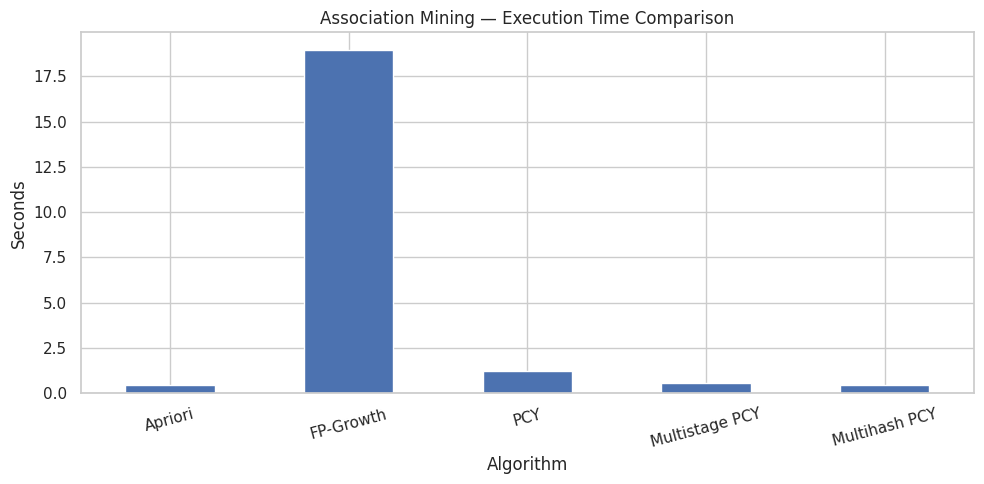

In [26]:
association_comparison = pd.DataFrame([
    {"Algorithm":"Apriori", "Frequent itemsets":len(apriori_itemsets), "Execution time (sec)":apriori_time},
    {"Algorithm":"FP-Growth", "Frequent itemsets":len(fp_itemsets), "Execution time (sec)":fp_time},
    {"Algorithm":"PCY", "Frequent itemsets (pairs)":len(pcy_result["frequent_pairs"]), "Execution time (sec)":pcy_time},
    {"Algorithm":"Multistage PCY", "Frequent itemsets (pairs)":len(multistage_pairs), "Execution time (sec)":multistage_time},
    {"Algorithm":"Multihash PCY", "Frequent itemsets (pairs)":len(multihash_pairs), "Execution time (sec)":multihash_time}
])
display(association_comparison.round(4))

association_comparison.set_index("Algorithm")["Execution time (sec)"].plot(
    kind="bar", figsize=(10,5), rot=15
)
plt.title("Association Mining — Execution Time Comparison")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

## Step 25: Unsupervised Clustering Algorithm Comparison

This section compares the performance of our three clustering methods: K-Means, Agglomerative Hierarchical, and DBSCAN.

### Comparison Metrics:
- **Cluster Counts**: How many distinct groupings were identified by each algorithm.
- **Outliers**: The volume of noise or anomalous data points detected (especially by DBSCAN).
- **Silhouette Scores**: Measures cluster separation and cohesion to compare the quality of the groupings across models.

In [27]:
clustering_comparison = pd.DataFrame([
    {"Algorithm":"K-Means", "Clusters":len(np.unique(kmeans_labels)), "Noise points":0,
     "Silhouette":silhouette_score(X_cluster, kmeans_labels, sample_size=min(4000,len(X_cluster)), random_state=RANDOM_STATE)},
    {"Algorithm":"Agglomerative", "Clusters":len(np.unique(hier_labels)), "Noise points":0,
     "Silhouette":silhouette_score(X_hier, hier_labels)},
    {"Algorithm":"DBSCAN", "Clusters":n_clusters_db, "Noise points":n_noise,
     "Silhouette":(silhouette_score(X_cluster[non_noise_mask], db_labels[non_noise_mask],
                                   sample_size=min(4000, non_noise_mask.sum()), random_state=RANDOM_STATE)
                   if n_clusters_db >= 2 and non_noise_mask.sum() > 2 else np.nan)}
])
display(clustering_comparison.round(4))


,Algorithm,Clusters,Noise points,Silhouette
0,K-Means,4,0,0.3397
1,Agglomerative,4,0,0.2932
2,DBSCAN,1,101,NaN


## Step 26: Export Findings & Output Package Creation

To make our findings shareable, we export our key tables, metrics, and discovered rules as standard CSV files.

### Exported Assets:
1. Classification model comparisons and Random Forest feature importances.
2. Clustering algorithm results.
3. Association rules and frequent itemset files.
4. We package all files into a single ZIP archive, creating a clean output ready for reporting.

In [28]:
# Save important result tables in the Colab working directory
classification_comparison.to_csv("classification_comparison.csv", index=False)
clustering_comparison.to_csv("clustering_comparison.csv", index=False)
association_comparison.to_csv("association_comparison.csv", index=False)
rf_importance.to_csv("random_forest_feature_importance.csv", index=False)
apriori_itemsets.to_csv("apriori_frequent_itemsets.csv", index=False)
fp_itemsets.to_csv("fpgrowth_frequent_itemsets.csv", index=False)
pcy_pairs_df.to_csv("pcy_frequent_pairs.csv", index=False)

print("Saved result CSV files to the current Colab session.")
print("\\nCLASSIFICATION SUMMARY")
display(classification_comparison.round(4))
print("\\nCLUSTERING SUMMARY")
display(clustering_comparison.round(4))
print("\\nASSOCIATION MINING SUMMARY")
display(association_comparison.round(4))

# Optional: download a ZIP containing all result CSV files
import zipfile, os
output_files = [
    "classification_comparison.csv", "clustering_comparison.csv",
    "association_comparison.csv", "random_forest_feature_importance.csv",
    "apriori_frequent_itemsets.csv", "fpgrowth_frequent_itemsets.csv",
    "pcy_frequent_pairs.csv"
]
with zipfile.ZipFile("olympic_data_mining_results.zip", "w") as zf:
    for filename in output_files:
        if os.path.exists(filename):
            zf.write(filename)
print("\\nCreated olympic_data_mining_results.zip")

Saved result CSV files to the current Colab session.
\nCLASSIFICATION SUMMARY


,Algorithm,Accuracy,Precision,Recall,F1-score,Training time (sec)
0,ID3-style (Entropy),0.5894,0.2188,0.6940,0.3327,2.5339
1,CART (Gini),0.5825,0.2162,0.6973,0.3300,2.5389
2,Random Forest,0.6920,0.2641,0.6097,0.3686,70.0548
3,XGBoost,0.8581,0.7270,0.0606,0.1119,3.7979
4,Naïve Bayes,0.8341,0.3192,0.1104,0.1640,0.8977


\nCLUSTERING SUMMARY


,Algorithm,Clusters,Noise points,Silhouette
0,K-Means,4,0,0.3397
1,Agglomerative,4,0,0.2932
2,DBSCAN,1,101,NaN


\nASSOCIATION MINING SUMMARY


,Algorithm,Frequent itemsets,Execution time (sec),Frequent itemsets (pairs)
0,Apriori,308.0,0.4878,NaN
1,FP-Growth,308.0,18.9745,NaN
2,PCY,NaN,1.2344,132.0
3,Multistage PCY,NaN,0.5605,132.0
4,Multihash PCY,NaN,0.4754,132.0


\nCreated olympic_data_mining_results.zip


## Step 27: Conclusion & Key Takeaways

### Summary of Project Phases:
1. **Data Preprocessing**: Handled missing values, scaled continuous attributes, and encoded categorical variables into numeric vectors.
2. **Supervised Classification**: Evaluated ID3, CART, Random Forests, XGBoost, and Naïve Bayes, using precision, recall, and F1-score to assess performance on imbalanced classes.
3. **Unsupervised Clustering**: Used K-Means, Agglomerative, and DBSCAN to segment athletes, evaluating groups using silhouette scores and PCA projections.
4. **Association Rule Mining**: Analyzed relationships among athlete attributes using Apriori and FP-Growth, and compared their performance to optimized PCY variants (PCY, Multistage, and Multihash).